In [33]:
import numpy as np
import torch
import copy
import matplotlib.pyplot as plt
from envs.multi_agent_env import StagHuntEnv

# ── 유틸리티 함수 ────────────────────────────────────────────────────────────

def patch_env_for_cloning(env):
    """환경 인스턴스에 상태 저장/복원 기능을 동적으로 추가합니다."""
    def get_env_state():
        return copy.deepcopy(env.__dict__)
    
    def set_env_state(state):
        env.__dict__.update(copy.deepcopy(state))
        
    env.get_env_state = get_env_state
    env.set_env_state = set_env_state
    return env

def obs_dict_to_tensor(obs_dict, device):
    """환경에서 반환된 obs dict를 torch tensor dict로 변환합니다."""
    return {
        i: torch.tensor(v, dtype=torch.float32, device=device)
        for i, v in obs_dict.items()
    }

def save_policy_rnn_states(policy):
    """policy 내부의 모든 에이전트 RNN hidden state를 저장합니다."""
    return {
        agent_id: (
            agent.rnn_state_policy.clone(),
            agent.prev_action.clone(),
        )
        for agent_id, agent in policy.agents.items()
    }

def restore_policy_rnn_states(policy, saved_states):
    """save_policy_rnn_states로 저장한 상태를 policy에 복원합니다."""
    for agent_id, (rnn_state, prev_action) in saved_states.items():
        policy.agents[agent_id].rnn_state_policy = rnn_state.clone()
        policy.agents[agent_id].prev_action = prev_action.clone()

def get_w_x(obs_dict, policy, agent_i, device):
    """
    W^i_t, X^i_t를 구성합니다.
    W^i_t = O_t^{-i}
    X^i_t = (O_t^i, H_{t-1}^{-i})
    """
    n = len(obs_dict)
    w_parts = [
        obs_dict[j] if isinstance(obs_dict[j], torch.Tensor)
        else torch.tensor(obs_dict[j], dtype=torch.float32, device=device)
        for j in range(n) if j != agent_i
    ]
    w_t_i = torch.cat(w_parts, dim=-1)
    obs_i = obs_dict[agent_i] if isinstance(obs_dict[agent_i], torch.Tensor) \
        else torch.tensor(obs_dict[agent_i], dtype=torch.float32, device=device)
    h_others_parts = [
        policy.agents[j].rnn_state_policy.view(-1)
        for j in range(n) if j != agent_i
    ]
    h_others = torch.cat(h_others_parts, dim=-1)
    x_t_i = torch.cat([obs_i, h_others], dim=-1)
    return w_t_i, x_t_i

# ── 환경 초기화 ──────────────────────────────────────────────────────────────
env_config = {
    "num_agents": 3,
    "max_steps": 50,
    "stag_move_prob": 0.0,
    "coop_bonus": 0.0,
    "forage_reward": 3.0,
    "stag_reward": 5.0,
    "mauling_punishment": 0.0,
    "grid_observation": True,
    "obs_noise_std": 0.1
}

env = patch_env_for_cloning(StagHuntEnv(**env_config))
device = 'cpu'
print("✅ 환경 및 유틸리티 함수 초기화 완료")


✅ 환경 및 유틸리티 함수 초기화 완료


In [ ]:
# ── 헬퍼 함수: NaivePredictor 및 Policy 로드 ───────────────────────────────
def load_all_models(checkpoint_path, naive_checkpoint_path, env, device,
                     alg_num_agents=3, alg_action_dim=5,
                     alg_hidden_dim=64, alg_recurrent_N=1):
    from algorithms.r_pci import rPCIAlgorithm
    from algorithms.networks import NaivePredictor
    import os
    
    obs_dim = env.get_obs_dim()
    x_dim = obs_dim + (alg_num_agents - 1) * alg_hidden_dim * alg_recurrent_N

    # 1. PCI Policy 로드
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    algorithm_state = checkpoint['algorithm_state']

    policy = rPCIAlgorithm(
        env=env, num_agents=alg_num_agents, obs_dim=obs_dim, action_dim=alg_action_dim,
        w_dim=obs_dim * (alg_num_agents - 1), hidden_dim=alg_hidden_dim, recurrent_N=alg_recurrent_N, device=device,
    )
    for agent_id, agent_state in algorithm_state['agents'].items():
        policy.agents[agent_id].policy_net.load_state_dict(agent_state['policy_net'])
        policy.agents[agent_id].policy_net.eval()
    policy.outcome_bridge_net.load_state_dict(algorithm_state['outcome_bridge_net'])
    policy.outcome_bridge_net.eval()

    # 2. NaivePredictor 로드 (경로가 있을 때만)
    naive_predictor = None
    if naive_checkpoint_path and os.path.exists(naive_checkpoint_path):
        naive_predictor = NaivePredictor(
            action_dim=alg_action_dim, num_agents=alg_num_agents, x_dim=x_dim, hidden_dim=alg_hidden_dim
        ).to(device)
        naive_checkpoint = torch.load(naive_checkpoint_path, map_location=device, weights_only=False)
        naive_predictor.load_state_dict(naive_checkpoint['naive_predictor_state'])
        naive_predictor.eval()
    
    return policy, policy.outcome_bridge_net, naive_predictor

# ── 헬퍼 함수: 고속 오프폴리씨 평가 ──────────────────────────────────────────
def run_evaluation_off_policy(policy, outcome_bridge, naive_predictor, dataset, device):
    """
    저장된 전문가 데이터셋 위에서 모델을 고속으로 평가합니다.
    """
    mse_pci_list = []
    mse_naive_list = []
    
    # 모델의 RNN 상태 초기화
    policy.reset_agents()
    
    # 궤적을 따라가며 평가
    for step_data in dataset:
        obs_tensor = obs_dict_to_tensor(step_data['obs'], device)
        
        # 1. PCI & Naive 평가
        for agent_i in range(policy.num_agents):
            w_t_i, x_t_i = get_w_x(obs_tensor, policy, agent_i, device)
            
            # action intervention
            for a in range(policy.action_dim):
                mu_true = step_data['ground_truths'][(agent_i, a)]
                
                # PCI
                a_tensor = torch.tensor([a], dtype=torch.long, device=device)
                w_tensor = w_t_i.unsqueeze(0)
                x_tensor = x_t_i.unsqueeze(0)
                
                with torch.no_grad():
                    r_hat_all = outcome_bridge.forward(a_tensor, w_tensor, x=x_tensor)
                    pci_est = r_hat_all[0].sum().item()
                    mse_pci_list.append((mu_true - pci_est)**2)
                    
                    # Naive (있을 경우만)
                    if naive_predictor is not None:
                        r_hat_naive = naive_predictor.forward(a_tensor, x_tensor)
                        naive_est = r_hat_naive[0].sum().item()
                        mse_naive_list.append((mu_true - naive_est)**2)

        # 2. 모델의 RNN 은닉 상태 강제 업데이트 (Trajectory 복원)
        with torch.no_grad():
            policy.get_actions(obs_tensor)

    return {
        'pci_mse': np.mean(mse_pci_list),
        'naive_mse': np.mean(mse_naive_list) if mse_naive_list else None
    }


In [35]:
# ── 전문가 데이터셋 생성 (최초 1회 실행 권장) ──────────────────────────────────
# 성능이 가장 좋은 최종 모델을 사용해 정밀한 Ground Truth(MC 샘플링)가 포함된 궤적을 구축합니다.

GENERATE_DATA = True  # 데이터셋을 새로 생성하려면 True로 변경하세요.
DATA_SAVE_PATH = "expert_val_data.pt"

if GENERATE_DATA:
    print("🚀 전문가 데이터셋 생성을 시작합니다... (이 작업은 몇 분 정도 소요될 수 있습니다.)")
    NUM_EPISODES_GEN = 100
    K_MC_GEN = 50
    
    dataset = []
    
    # 최종 모델 로드 (전문가)
    expert_ckpt_path = "save_checkpoints/20260316_152607_seed43/staghuntenv/checkpoints/final_checkpoint.pt"
    pol_expert, _, _ = load_all_models(expert_ckpt_path, "", env, device)
    
    for ep in range(NUM_EPISODES_GEN):
        obs = env.reset()
        pol_expert.reset_agents()
        done = False
        step = 0
        
        while not done and step < 50:
            saved_env_state = env.get_env_state()
            saved_rnn_states = save_policy_rnn_states(pol_expert)
            obs_tensor = obs_dict_to_tensor(obs, device)

            step_data = {
                'obs': {k: v.cpu().numpy() for k, v in obs_tensor.items()},
                'rnn_states': {k: (v[0].cpu().numpy(), v[1].cpu().numpy()) for k, v in saved_rnn_states.items()},
                'ground_truths': {} # {(agent_i, action): mu_true}
            }

            for agent_i in range(pol_expert.num_agents):
                for a in range(pol_expert.action_dim):
                    mc_rewards = []
                    for _ in range(K_MC_GEN):
                        env.set_env_state(saved_env_state)
                        restore_policy_rnn_states(pol_expert, saved_rnn_states)
                        actions_dict = pol_expert.get_actions(obs_tensor)
                        actions_env = {j: actions_dict[j][0] for j in range(pol_expert.num_agents)}
                        actions_env[agent_i] = a
                        _, rewards, _, _ = env.step(actions_env)
                        mc_rewards.append(np.sum(list(rewards.values())))
                    step_data['ground_truths'][(agent_i, a)] = np.mean(mc_rewards)

            dataset.append(step_data)
            
            # 전문가 정책으로 실제 진행
            env.set_env_state(saved_env_state)
            restore_policy_rnn_states(pol_expert, saved_rnn_states)
            actions_dict = pol_expert.get_actions(obs_tensor)
            actions_env = {j: actions_dict[j][0] for j in range(pol_expert.num_agents)}
            obs, _, dones, _ = env.step(actions_env)
            done = all(dones) if isinstance(dones, (list, np.ndarray)) else dones
            step += 1
        
        print(f"  - Episode {ep+1}/{NUM_EPISODES_GEN} 완료")

    torch.save(dataset, DATA_SAVE_PATH)
    print(f"✅ 데이터셋 저장 완료: {DATA_SAVE_PATH} (총 {len(dataset)} 스텝)")
else:
    import os
    if os.path.exists(DATA_SAVE_PATH):
        print(f"ℹ️ 기존 데이터셋을 로드하여 사용합니다: {DATA_SAVE_PATH}")
    else:
        print(f"⚠️ {DATA_SAVE_PATH} 파일이 없습니다. GENERATE_DATA = True로 설정하여 먼저 생성하세요.")


🚀 전문가 데이터셋 생성을 시작합니다... (이 작업은 몇 분 정도 소요될 수 있습니다.)
  - Episode 1/100 완료
  - Episode 2/100 완료
  - Episode 3/100 완료
  - Episode 4/100 완료
  - Episode 5/100 완료
  - Episode 6/100 완료
  - Episode 7/100 완료
  - Episode 8/100 완료
  - Episode 9/100 완료
  - Episode 10/100 완료
  - Episode 11/100 완료
  - Episode 12/100 완료
  - Episode 13/100 완료
  - Episode 14/100 완료
  - Episode 15/100 완료
  - Episode 16/100 완료
  - Episode 17/100 완료
  - Episode 18/100 완료
  - Episode 19/100 완료
  - Episode 20/100 완료
  - Episode 21/100 완료
  - Episode 22/100 완료
  - Episode 23/100 완료
  - Episode 24/100 완료
  - Episode 25/100 완료
  - Episode 26/100 완료
  - Episode 27/100 완료
  - Episode 28/100 완료
  - Episode 29/100 완료
  - Episode 30/100 완료
  - Episode 31/100 완료
  - Episode 32/100 완료
  - Episode 33/100 완료
  - Episode 34/100 완료
  - Episode 35/100 완료
  - Episode 36/100 완료
  - Episode 37/100 완료
  - Episode 38/100 완료
  - Episode 39/100 완료
  - Episode 40/100 완료
  - Episode 41/100 완료
  - Episode 42/100 완료
  - Episode 43/100 완료
  - Episode 

In [36]:
# ── 고속 오프폴리씨 평가 실행 ──────────────────────────────────────────────
DATA_PATH = "expert_val_data.pt"
import os
if not os.path.exists(DATA_PATH):
    print(f"❌ '{DATA_PATH}' 파일이 없습니다. 상단의 생성 셀을 먼저 실행하세요.")
else:
    val_dataset = torch.load(DATA_PATH, weights_only=False)
    print(f"📋 데이터셋 로드 완료 ({len(val_dataset)} 스텝)")

    pci_base_dir = "save_checkpoints/20260316_152607_seed43/staghuntenv/checkpoints"
    naive_base_dir = "save_checkpoints/20260316_152607_seed43/staghuntenv/checkpoints_naivepredictor"

    target_itrs = [0, 500, 1000, 1499]
    comparison_results = {}

    for itr in target_itrs:
        pci_filename = "final_checkpoint.pt" if itr == 1499 else f"checkpoint_{itr}.pt"
        naive_filename = "final_checkpoint.pt" if itr == 1499 else f"checkpoint_{itr}.pt"
        
        pci_path = f"{pci_base_dir}/{pci_filename}"
        naive_path = f"{naive_base_dir}/{naive_filename}"
        
        print(f"🔍 Iteration {itr} 평가 중...")
        pol, ob, nv = load_all_models(pci_path, naive_path, env, device)
        
        metrics = run_evaluation_off_policy(pol, ob, nv, val_dataset, device)
        comparison_results[itr] = metrics
        
        msg = f"  → PCI MSE: {metrics['pci_mse']:.4f}"
        if metrics['naive_mse'] is not None:
            msg += f" | Naive MSE: {metrics['naive_mse']:.4f}"
        print(msg)

    print("\n✅ 모든 체크포인트 평가 완료!")


📋 데이터셋 로드 완료 (100 스텝)
🔍 Iteration 0 평가 중...
  → PCI MSE: 3.5412 | Naive MSE: 3.6771
🔍 Iteration 500 평가 중...
  → PCI MSE: 0.1912 | Naive MSE: 2.8638
🔍 Iteration 1000 평가 중...
  → PCI MSE: 0.2165 | Naive MSE: 2.9071
🔍 Iteration 1499 평가 중...
  → PCI MSE: 0.2816 | Naive MSE: 2.9211

✅ 모든 체크포인트 평가 완료!


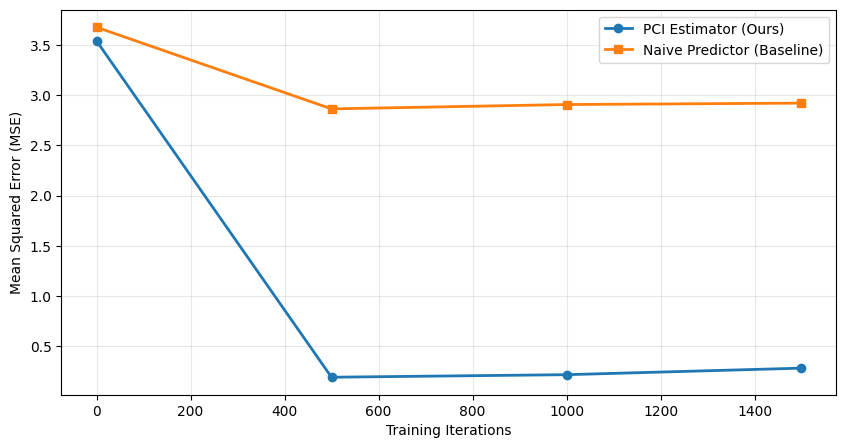

In [37]:
# ── 결과 시각화: Learning Curve ──────────────────────────────────────────────
itrs = sorted(comparison_results.keys())
pci_mses = [comparison_results[i]['pci_mse'] for i in itrs]
naive_mses = [comparison_results[i]['naive_mse'] for i in itrs]

plt.figure(figsize=(10, 5))
plt.plot(itrs, pci_mses, marker='o', label='PCI Estimator (Ours)', linewidth=2)
if all(m is not None for m in naive_mses):
    plt.plot(itrs, naive_mses, marker='s', label='Naive Predictor (Baseline)', linewidth=2)

plt.xlabel("Training Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
